# 1. Setup & Imports

In [ ]:
import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import seaborn as sns

from statsmodels.tsa.holtwinters import ExponentialSmoothing
from statsmodels.tsa.statespace.sarimax import SARIMAX
from statsmodels.tsa.seasonal import seasonal_decompose
from statsmodels.tsa.stattools import adfuller

from sklearn.ensemble import RandomForestRegressor
from xgboost import XGBRegressor
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

%matplotlib inline
sns.set_style('whitegrid')
plt.rcParams['figure.figsize'] = (11, 5)
plt.rcParams['axes.titlesize'] = 13
plt.rcParams['axes.titleweight'] = 'bold'

RAIN_BLUE = '#1f6fb2'
DRY_ORANGE = '#e08214'
PALETTE = ['#08519c', '#3182bd', '#6baed6', '#9ecae1', '#c6dbef']

RANDOM_STATE = 42
print("Libraries loaded.")

Libraries loaded.


# 2. Data Loading & Overview

In [ ]:
data_path = "mumbai-monthly-rains.csv"
df = pd.read_csv(data_path)
print("Shape:", df.shape)
df.head()

Shape: (121, 14)


,Year,Jan,Feb,Mar,April,May,June,July,Aug,Sept,Oct,Nov,Dec,Total
0,1901,13.116602,0.000000,0.000000,3.949669,17.139791,640.714036,888.369692,545.045796,64.271513,9.871696,0.000000,0.000000,2182.478796
1,1902,0.000000,0.000000,0.000000,0.000000,0.355001,247.998782,408.433730,566.595863,688.913455,28.654092,0.488864,19.526547,1960.966334
2,1903,0.000000,0.000000,0.844034,0.000000,220.568740,370.849048,902.447896,602.420828,264.589816,157.892877,0.000000,0.000000,2519.613240
3,1904,0.000000,0.000000,11.381769,0.000000,0.000000,723.081969,390.886799,191.581927,85.704754,38.679948,0.000000,0.000000,1441.317168
4,1905,0.662561,1.713452,0.000000,0.000000,0.000000,123.870892,581.827975,167.382149,172.297723,7.365924,24.903575,0.000000,1080.024250


In [ ]:
df.info()
print()
print("Missing values per column:")
print(df.isna().sum().sum(), "total missing cells")

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 121 entries, 0 to 120
Data columns (total 14 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   Year    121 non-null    int64  
 1   Jan     121 non-null    float64
 2   Feb     121 non-null    float64
 3   Mar     121 non-null    float64
 4   April   121 non-null    float64
 5   May     121 non-null    float64
 6   June    121 non-null    float64
 7   July    121 non-null    float64
 8   Aug     121 non-null    float64
 9   Sept    121 non-null    float64
 10  Oct     121 non-null    float64
 11  Nov     121 non-null    float64
 12  Dec     121 non-null    float64
 13  Total   121 non-null    float64
dtypes: float64(13), int64(1)
memory usage: 13.4 KB

Missing values per column:
0 total missing cells


In [ ]:
df.describe().T.round(1)

,count,mean,std,min,25%,50%,75%,max
Year,121.0,1961.0,35.1,1901.0,1931.0,1961.0,1991.0,2021.0
Jan,121.0,1.6,6.5,0.0,0.0,0.0,0.0,51.3
Feb,121.0,0.9,3.1,0.0,0.0,0.0,0.2,21.1
Mar,121.0,0.9,2.9,0.0,0.0,0.0,0.0,18.3
April,121.0,1.4,7.4,0.0,0.0,0.0,0.2,75.5
May,121.0,18.2,48.6,0.0,0.0,0.4,4.2,234.4
June,121.0,517.9,251.1,61.1,324.1,482.4,678.0,1219.5
July,121.0,757.4,285.8,103.2,540.7,788.4,942.6,1358.8
Aug,121.0,465.6,249.1,87.5,268.0,445.9,604.4,1201.0
Sept,121.0,312.9,205.1,36.3,149.6,269.3,398.6,987.8


In [ ]:
MONTHS = ['Jan','Feb','Mar','April','May','June','July','Aug','Sept','Oct','Nov','Dec']
recomputed_total = df[MONTHS].sum(axis=1)
max_diff = (recomputed_total - df['Total']).abs().max()
print(f"Max absolute difference between summed months and reported Total: {max_diff:.6f} mm")
print("-> Totals reconcile. Data is internally consistent, 121 years (1901-2021), no missing values.")

Max absolute difference between summed months and reported Total: 0.000000 mm
-> Totals reconcile. Data is internally consistent, 121 years (1901-2021), no missing values.


# 3. Reshaping to a Time Series

In [ ]:
MONTH_NUM = {m: i + 1 for i, m in enumerate(MONTHS)}

long_df = df.melt(id_vars=['Year'], value_vars=MONTHS, var_name='Month', value_name='Rainfall')
long_df['MonthNum'] = long_df['Month'].map(MONTH_NUM)
long_df['Date'] = pd.to_datetime(dict(year=long_df.Year, month=long_df.MonthNum, day=1))
long_df = long_df.sort_values('Date').reset_index(drop=True)[['Date', 'Year', 'MonthNum', 'Month', 'Rainfall']]

ts = long_df.set_index('Date')['Rainfall'].asfreq('MS')

full_range = pd.date_range(ts.index.min(), ts.index.max(), freq='MS')
print(f"Series length: {len(ts)} months, {ts.index.min().date()} to {ts.index.max().date()}")
print(f"Missing months in the continuous index: {full_range.difference(ts.index).size}")
long_df.head()

Series length: 1452 months, 1901-01-01 to 2021-12-01
Missing months in the continuous index: 0


,Date,Year,MonthNum,Month,Rainfall
0,1901-01-01,1901,1,Jan,13.116602
1,1901-02-01,1901,2,Feb,0.000000
2,1901-03-01,1901,3,Mar,0.000000
3,1901-04-01,1901,4,April,3.949669
4,1901-05-01,1901,5,May,17.139791


# 4. Exploratory Data Analysis

4.1 Annual rainfall trend

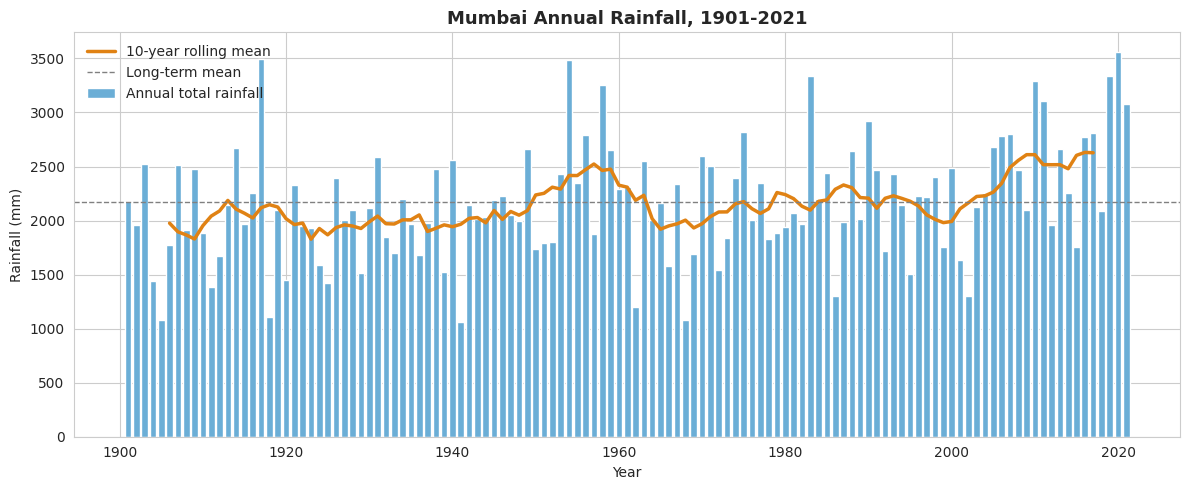

In [ ]:
import os

annual = df[['Year', 'Total']].copy()
annual['rolling10'] = annual['Total'].rolling(10, center=True).mean()

fig, ax = plt.subplots(figsize=(12, 5))
ax.bar(annual['Year'], annual['Total'], color=PALETTE[2], width=0.8, label='Annual total rainfall')
ax.plot(annual['Year'], annual['rolling10'], color=DRY_ORANGE, linewidth=2.5, label='10-year rolling mean')
ax.axhline(annual['Total'].mean(), color='grey', linestyle='--', linewidth=1, label='Long-term mean')
ax.set_title('Mumbai Annual Rainfall, 1901-2021')
ax.set_xlabel('Year'); ax.set_ylabel('Rainfall (mm)')
ax.legend(frameon=False)
plt.tight_layout()
os.makedirs('figures', exist_ok=True) # Create the directory if it doesn't exist
plt.savefig('figures/annual_trend.png', dpi=140)
plt.show()

In [ ]:
from scipy import stats
slope, intercept, r, p, se = stats.linregress(annual['Year'], annual['Total'])
print(f"Linear trend: {slope:.2f} mm/year (p-value = {p:.3f}, R^2 = {r**2:.3f})")
if p < 0.05:
    print("-> Statistically significant long-term trend in annual rainfall.")
else:
    print("-> No statistically significant long-term trend; year-to-year variability dominates.")

Linear trend: 4.78 mm/year (p-value = 0.000, R^2 = 0.099)
-> Statistically significant long-term trend in annual rainfall.


4.2 Seasonal (monthly) pattern

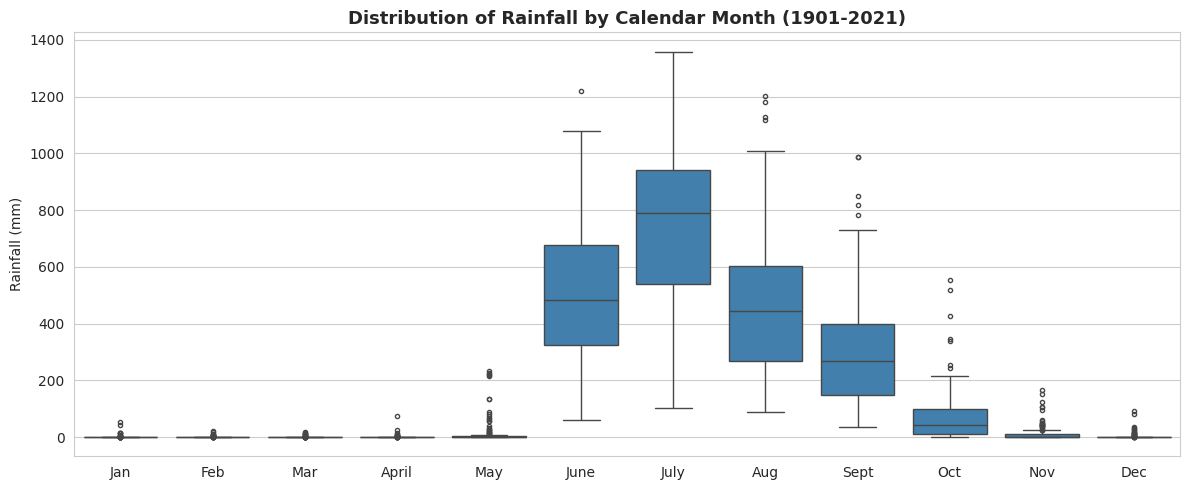

In [ ]:
order = MONTHS
fig, ax = plt.subplots(figsize=(12, 5))
sns.boxplot(data=long_df, x='Month', y='Rainfall', order=order, ax=ax,
            color=PALETTE[1], fliersize=3)
ax.set_title('Distribution of Rainfall by Calendar Month (1901-2021)')
ax.set_xlabel(''); ax.set_ylabel('Rainfall (mm)')
plt.tight_layout(); plt.savefig('figures/monthly_boxplot.png', dpi=140); plt.show()

In [ ]:
monthly_stats = long_df.groupby('Month')['Rainfall'].agg(['mean', 'std', 'max']).reindex(order)
monthly_stats['cv'] = (monthly_stats['std'] / monthly_stats['mean']).round(2)
monthly_stats.round(1)

,mean,std,max,cv
Month,,,,
Jan,1.6,6.5,51.3,4.1
Feb,0.9,3.1,21.1,3.3
Mar,0.9,2.9,18.3,3.3
April,1.4,7.4,75.5,5.2
May,18.2,48.6,234.4,2.7
June,517.9,251.1,1219.5,0.5
July,757.4,285.8,1358.8,0.4
Aug,465.6,249.1,1201.0,0.5
Sept,312.9,205.1,987.8,0.7


4.3 Year x Month heatmap

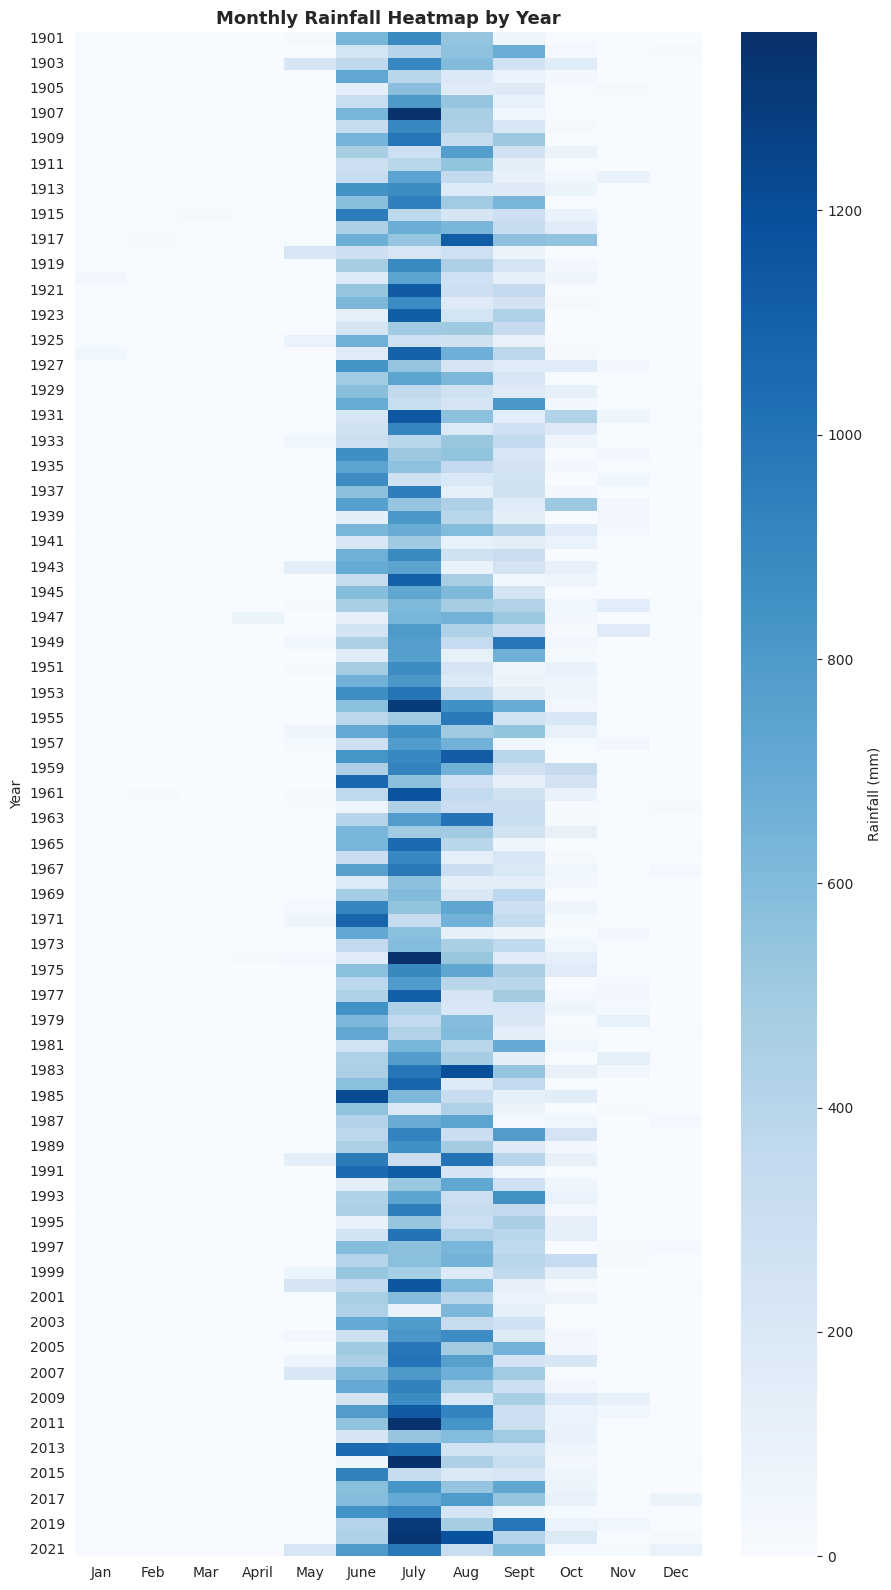

In [ ]:
pivot = df.set_index('Year')[MONTHS]
fig, ax = plt.subplots(figsize=(9, 16))
sns.heatmap(pivot, cmap='Blues', ax=ax, cbar_kws={'label': 'Rainfall (mm)'})
ax.set_title('Monthly Rainfall Heatmap by Year')
plt.tight_layout(); plt.savefig('figures/heatmap.png', dpi=140); plt.show()

4.4 Seasonal decomposition

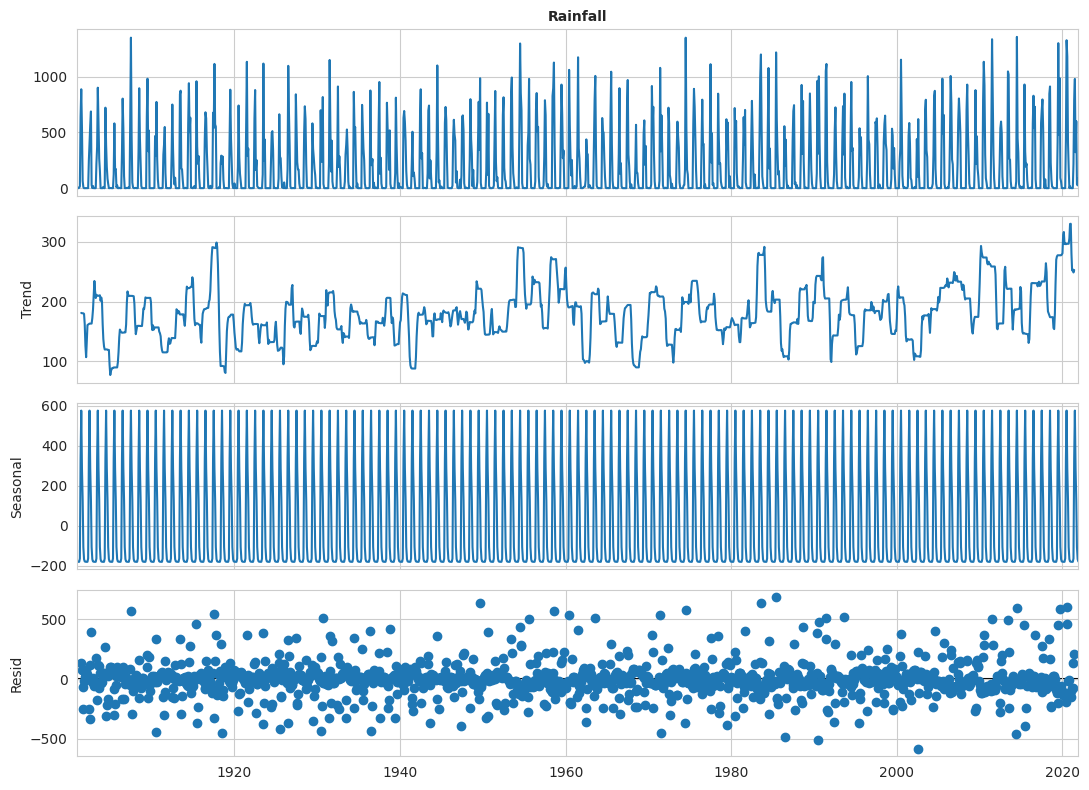

In [ ]:
decomp = seasonal_decompose(ts, model='additive', period=12)
fig = decomp.plot()
fig.set_size_inches(11, 8)
for a in fig.axes:
    a.title.set_size(10)
plt.tight_layout(); plt.savefig('figures/decomposition.png', dpi=140); plt.show()

In [ ]:
season_var = decomp.seasonal.var()
resid_var = decomp.resid.dropna().var()
trend_var = decomp.trend.dropna().var()
total = season_var + resid_var + trend_var
print(f"Share of variance -> seasonal: {season_var/total:.1%}, trend: {trend_var/total:.1%}, residual: {resid_var/total:.1%}")

Share of variance -> seasonal: 74.8%, trend: 2.2%, residual: 23.0%


4.5 Stationarity check

In [ ]:
adf_result = adfuller(ts)
print(f"ADF statistic: {adf_result[0]:.3f}")
print(f"p-value: {adf_result[1]:.4f}")
print("-> Series is stationary (reject unit root)" if adf_result[1] < 0.05
      else "-> Series is non-stationary; differencing may help SARIMA")

ADF statistic: -5.592
p-value: 0.0000
-> Series is stationary (reject unit root)


# 5. Feature Engineering

In [ ]:
def make_features(s, lags=(1, 2, 3, 12)):
    d = pd.DataFrame({'y': s})
    for lag in lags:
        d[f'lag{lag}'] = s.shift(lag)
    d['month'] = s.index.month
    d['month_sin'] = np.sin(2 * np.pi * d['month'] / 12)
    d['month_cos'] = np.cos(2 * np.pi * d['month'] / 12)
    d['year'] = s.index.year
    d['roll_mean_3'] = s.shift(1).rolling(3).mean()
    d['roll_mean_12'] = s.shift(1).rolling(12).mean()
    return d.dropna()

feat = make_features(ts)
feat.head()

,y,lag1,lag2,lag3,lag12,month,month_sin,month_cos,year,roll_mean_3,roll_mean_12
Date,,,,,,,,,,,
1902-01-01,0.000000,0.0,0.0,9.871696,13.116602,1,0.500000,8.660254e-01,1902,3.290565,181.873233
1902-02-01,0.000000,0.0,0.0,0.000000,0.000000,2,0.866025,5.000000e-01,1902,0.000000,180.780183
1902-03-01,0.000000,0.0,0.0,0.000000,0.000000,3,1.000000,6.123234e-17,1902,0.000000,180.780183
1902-04-01,0.000000,0.0,0.0,0.000000,3.949669,4,0.866025,-5.000000e-01,1902,0.000000,180.780183
1902-05-01,0.355001,0.0,0.0,0.000000,17.139791,5,0.500000,-8.660254e-01,1902,0.000000,180.451044


# 6. Train / Test Split

In [ ]:
TEST_YEARS = 10
split_date = ts.index.max() - pd.DateOffset(years=TEST_YEARS) + pd.DateOffset(months=1)

train, test = ts[ts.index < split_date], ts[ts.index >= split_date]
print(f"Train: {train.index.min().date()} -> {train.index.max().date()}  ({len(train)} months)")
print(f"Test:  {test.index.min().date()} -> {test.index.max().date()}  ({len(test)} months)")

feat_train, feat_test = feat[feat.index < split_date], feat[feat.index >= split_date]
Xtr, ytr = feat_train.drop(columns='y'), feat_train['y']
Xte, yte = feat_test.drop(columns='y'), feat_test['y']

Train: 1901-01-01 -> 2011-12-01  (1332 months)
Test:  2012-01-01 -> 2021-12-01  (120 months)


# 7. Candidate Models

In [ ]:
def smape(y_true, y_pred):
    y_true, y_pred = np.array(y_true), np.array(y_pred)
    denom = np.abs(y_true) + np.abs(y_pred)
    denom[denom == 0] = 1
    return 100 * np.mean(2 * np.abs(y_pred - y_true) / denom)

results = []
def evaluate(name, y_true, y_pred):
    rmse = np.sqrt(mean_squared_error(y_true, y_pred))
    mae = mean_absolute_error(y_true, y_pred)
    r2 = r2_score(y_true, y_pred)
    sm = smape(y_true, y_pred)
    results.append(dict(Model=name, RMSE=rmse, MAE=mae, R2=r2, SMAPE=sm))
    print(f"{name:32s} RMSE={rmse:7.2f}  MAE={mae:7.2f}  R2={r2:6.3f}  SMAPE={sm:6.1f}%")

7.1 Climatology baseline

In [ ]:
clim = train.groupby(train.index.month).mean()
pred_clim = test.index.month.map(clim)
evaluate('Climatology (monthly mean)', test.values, pred_clim)

Climatology (monthly mean)       RMSE= 187.82  MAE=  95.19  R2= 0.712  SMAPE= 121.5%


7.2 Seasonal naive

In [ ]:
pred_naive = ts.shift(12).loc[test.index]
evaluate('Seasonal Naive (lag-12)', test.values, pred_naive.values)

Seasonal Naive (lag-12)          RMSE= 283.63  MAE= 144.74  R2= 0.344  SMAPE=  85.2%


7.3 Holt-Winters Exponential Smoothing

In [ ]:
hw_add = ExponentialSmoothing(train, trend=None, seasonal='add', seasonal_periods=12).fit()
pred_hw_add = hw_add.forecast(len(test)).clip(lower=0)
evaluate('Holt-Winters (additive)', test.values, pred_hw_add.values)

train_pos = train + 1  # multiplicative seasonality requires strictly positive values
hw_mul = ExponentialSmoothing(train_pos, trend=None, seasonal='mul', seasonal_periods=12).fit()
pred_hw_mul = (hw_mul.forecast(len(test)) - 1).clip(lower=0)
evaluate('Holt-Winters (multiplicative)', test.values, pred_hw_mul.values)

Holt-Winters (additive)          RMSE= 185.43  MAE= 117.20  R2= 0.720  SMAPE= 126.6%
Holt-Winters (multiplicative)    RMSE= 187.52  MAE=  95.72  R2= 0.713  SMAPE= 121.7%


/usr/local/lib/python3.12/dist-packages/statsmodels/tsa/holtwinters/model.py:903: ConvergenceWarning: Optimization failed to converge. Check mle_retvals.
  warnings.warn(


7.4 SARIMA

In [ ]:
sarima = SARIMAX(train, order=(1, 0, 1), seasonal_order=(1, 1, 1, 12),
                  enforce_stationarity=False, enforce_invertibility=False).fit(disp=False)
pred_sarima = sarima.forecast(len(test)).clip(lower=0)
evaluate('SARIMA(1,0,1)(1,1,1)[12]', test.values, pred_sarima.values)

SARIMA(1,0,1)(1,1,1)[12]         RMSE= 186.89  MAE=  94.90  R2= 0.715  SMAPE= 121.3%


7.5 Random Forest & XGBoost

In [ ]:
rf = RandomForestRegressor(n_estimators=300, max_depth=8, random_state=RANDOM_STATE)
rf.fit(Xtr, ytr)
pred_rf = rf.predict(Xte)
evaluate('Random Forest', yte.values, pred_rf)

xgb = XGBRegressor(n_estimators=300, max_depth=4, learning_rate=0.05, random_state=RANDOM_STATE)
xgb.fit(Xtr, ytr)
pred_xgb = xgb.predict(Xte)
evaluate('XGBoost', yte.values, pred_xgb)

Random Forest                    RMSE= 187.64  MAE= 100.96  R2= 0.713  SMAPE= 122.0%
XGBoost                          RMSE= 197.05  MAE= 105.69  R2= 0.684  SMAPE= 128.5%


# 8. Model Comparison

In [ ]:
results_df = pd.DataFrame(results).sort_values('RMSE').reset_index(drop=True)
results_df.round(2)

,Model,RMSE,MAE,R2,SMAPE
0,Holt-Winters (additive),185.43,117.20,0.72,126.57
1,"SARIMA(1,0,1)(1,1,1)[12]",186.89,94.90,0.72,121.31
2,Holt-Winters (multiplicative),187.52,95.72,0.71,121.74
3,Random Forest,187.64,100.96,0.71,121.99
4,Climatology (monthly mean),187.82,95.19,0.71,121.55
5,XGBoost,197.05,105.69,0.68,128.49
6,Seasonal Naive (lag-12),283.63,144.74,0.34,85.19


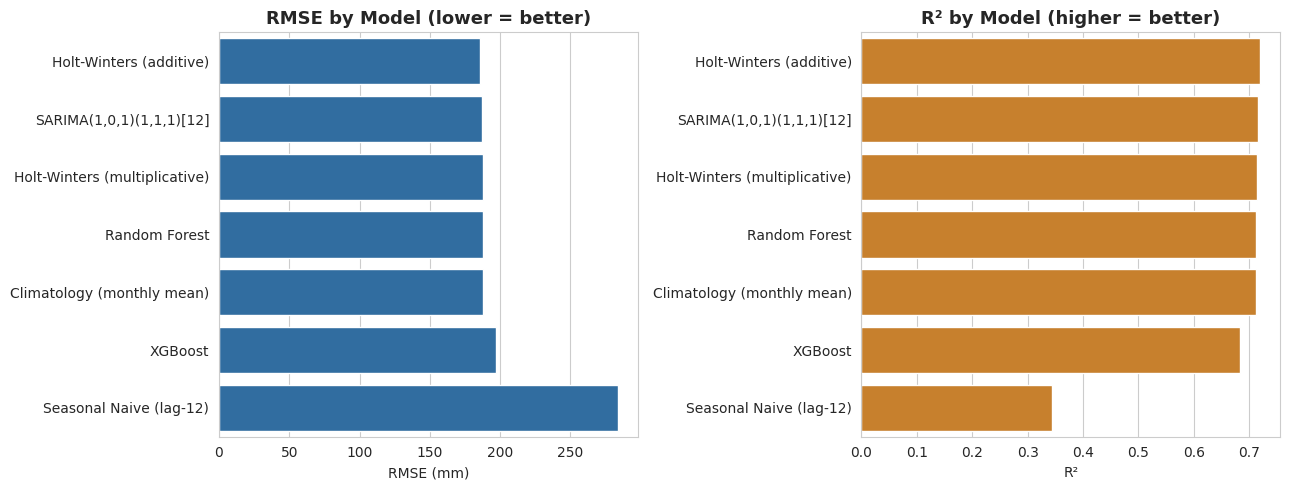

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
order_models = results_df.sort_values('RMSE')['Model']

sns.barplot(data=results_df, y='Model', x='RMSE', order=order_models, ax=axes[0], color=RAIN_BLUE)
axes[0].set_title('RMSE by Model (lower = better)')
axes[0].set_xlabel('RMSE (mm)'); axes[0].set_ylabel('')

sns.barplot(data=results_df, y='Model', x='R2', order=order_models, ax=axes[1], color=DRY_ORANGE)
axes[1].set_title('R\u00b2 by Model (higher = better)')
axes[1].set_xlabel('R\u00b2'); axes[1].set_ylabel('')

plt.tight_layout(); plt.savefig('figures/model_comparison.png', dpi=140); plt.show()

# 9. Hyperparameter Tuning

In [ ]:
import itertools

orders = [(0, 0, 1), (1, 0, 0), (1, 0, 1), (2, 0, 1)]
seasonal_orders = [(0, 1, 1, 12), (1, 1, 0, 12), (1, 1, 1, 12)]

grid_results = []
for p, d, q in orders:
    for P, D, Q, s in seasonal_orders:
        try:
            m = SARIMAX(train, order=(p, d, q), seasonal_order=(P, D, Q, s),
                        enforce_stationarity=False, enforce_invertibility=False).fit(disp=False)
            pred = m.forecast(len(test)).clip(lower=0)
            rmse = np.sqrt(mean_squared_error(test, pred))
            mae = mean_absolute_error(test, pred)
            grid_results.append(dict(order=(p, d, q), seasonal_order=(P, D, Q, s),
                                      aic=m.aic, rmse=rmse, mae=mae))
        except Exception:
            continue

grid_df = pd.DataFrame(grid_results).sort_values('rmse').reset_index(drop=True)
grid_df.round(2).head(8)

/usr/local/lib/python3.12/dist-packages/statsmodels/base/model.py:607: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  warnings.warn("Maximum Likelihood optimization failed to "
/usr/local/lib/python3.12/dist-packages/statsmodels/base/model.py:607: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  warnings.warn("Maximum Likelihood optimization failed to "


,order,seasonal_order,aic,rmse,mae
0,"(0, 0, 1)","(0, 1, 1, 12)",16729.57,186.26,94.68
1,"(1, 0, 0)","(0, 1, 1, 12)",16741.36,186.26,94.68
2,"(1, 0, 1)","(0, 1, 1, 12)",16731.28,186.39,94.73
3,"(2, 0, 1)","(0, 1, 1, 12)",16731.57,186.39,94.72
4,"(0, 0, 1)","(1, 1, 1, 12)",16730.55,186.73,94.84
5,"(1, 0, 0)","(1, 1, 1, 12)",16742.33,186.74,94.85
6,"(1, 0, 1)","(1, 1, 1, 12)",16732.26,186.89,94.90
7,"(2, 0, 1)","(1, 1, 1, 12)",16738.79,187.30,96.75


In [ ]:
best_sarima_params = grid_df.iloc[0]
print("Best SARIMA configuration by hold-out RMSE:")
print(f"  order={best_sarima_params['order']}, seasonal_order={best_sarima_params['seasonal_order']}")
print(f"  RMSE={best_sarima_params['rmse']:.2f}, MAE={best_sarima_params['mae']:.2f}, AIC={best_sarima_params['aic']:.1f}")

tuned_rmse = best_sarima_params['rmse']
hw_rmse = results_df.loc[results_df['Model'] == 'Holt-Winters (additive)', 'RMSE'].values[0]
print()
print(f"Tuned SARIMA RMSE: {tuned_rmse:.2f}  vs.  Holt-Winters (additive) RMSE: {hw_rmse:.2f}")

Best SARIMA configuration by hold-out RMSE:
  order=(0, 0, 1), seasonal_order=(0, 1, 1, 12)
  RMSE=186.26, MAE=94.68, AIC=16729.6

Tuned SARIMA RMSE: 186.26  vs.  Holt-Winters (additive) RMSE: 185.43


# 10. Final Model: Refit on Full History & Forecast

In [ ]:
FORECAST_HORIZON = 24  # months

final_model = ExponentialSmoothing(ts, trend=None, seasonal='add', seasonal_periods=12).fit()
forecast = final_model.forecast(FORECAST_HORIZON).clip(lower=0)
forecast.index.name = 'Date'
forecast_df = forecast.reset_index().rename(columns={0: 'Forecast_Rainfall_mm'})
forecast_df.columns = ['Date', 'Forecast_Rainfall_mm']
forecast_df['Date'] = forecast_df['Date'].dt.strftime('%Y-%m')
forecast_df.round(1)

,Date,Forecast_Rainfall_mm
0,2022-01,33.9
1,2022-02,33.2
2,2022-03,33.2
3,2022-04,33.7
4,2022-05,50.4
5,2022-06,550.0
6,2022-07,789.6
7,2022-08,497.7
8,2022-09,345.0
9,2022-10,106.0


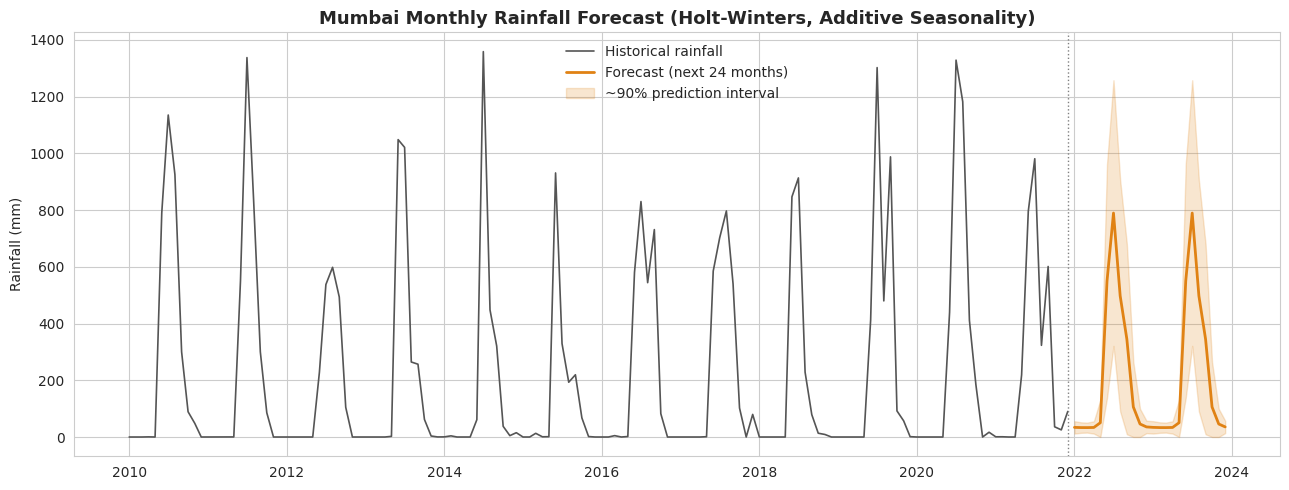

In [ ]:
# approximate 90% prediction interval using in-sample residual std by calendar month
resid = final_model.resid
resid_std_by_month = resid.groupby(resid.index.month).std()
z = 1.645  # ~90% interval

fc = final_model.forecast(FORECAST_HORIZON).clip(lower=0)
fc_std = fc.index.month.map(resid_std_by_month)
lower = (fc - z * fc_std).clip(lower=0)
upper = fc + z * fc_std

fig, ax = plt.subplots(figsize=(13, 5))
history = ts[ts.index >= '2010-01-01']
ax.plot(history.index, history.values, color='#555555', label='Historical rainfall', linewidth=1.2)
ax.plot(fc.index, fc.values, color=DRY_ORANGE, linewidth=2, label='Forecast (next 24 months)')
ax.fill_between(fc.index, lower, upper, color=DRY_ORANGE, alpha=0.2, label='~90% prediction interval')
ax.axvline(ts.index.max(), color='grey', linestyle=':', linewidth=1)
ax.set_title('Mumbai Monthly Rainfall Forecast (Holt-Winters, Additive Seasonality)')
ax.set_ylabel('Rainfall (mm)'); ax.set_xlabel('')
ax.legend(frameon=False)
plt.tight_layout(); plt.savefig('figures/forecast.png', dpi=140); plt.show()

# 11. Annual Roll-Up & Long-Term Outlook

Forecasted annual totals (mm) - note: partial calendar years only cover the forecast horizon
2022    2554.2
2023    2554.2
dtype: float64


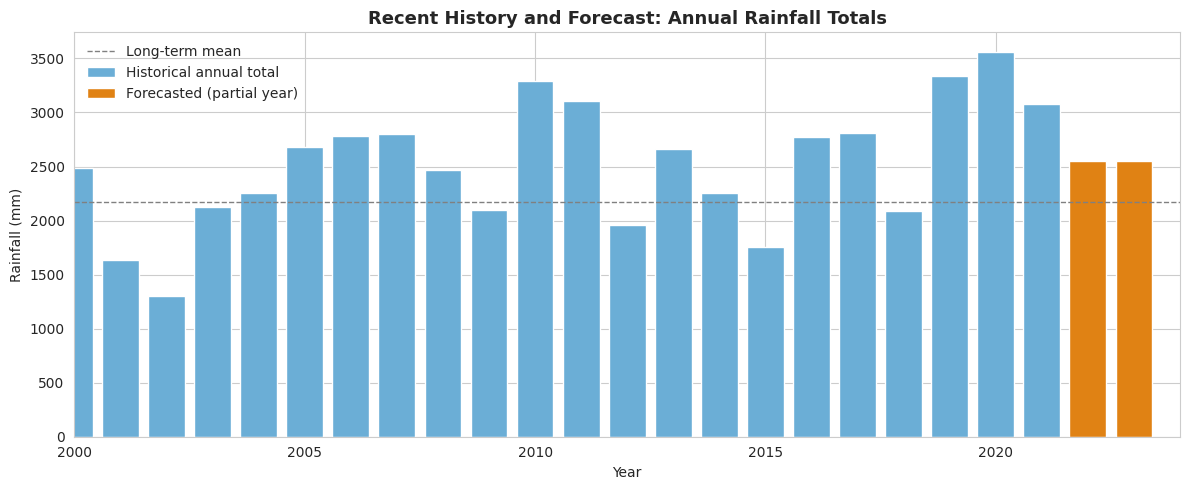

In [ ]:
forecast_annual = fc.groupby(fc.index.year).sum()
print("Forecasted annual totals (mm) - note: partial calendar years only cover the forecast horizon")
print(forecast_annual.round(1))

fig, ax = plt.subplots(figsize=(12, 5))
ax.bar(annual['Year'], annual['Total'], color=PALETTE[2], width=0.8, label='Historical annual total')
ax.bar(forecast_annual.index, forecast_annual.values, color=DRY_ORANGE, width=0.8, label='Forecasted (partial year)')
ax.axhline(annual['Total'].mean(), color='grey', linestyle='--', linewidth=1, label='Long-term mean')
ax.set_xlim(2000, forecast_annual.index.max() + 1)
ax.set_title('Recent History and Forecast: Annual Rainfall Totals')
ax.set_xlabel('Year'); ax.set_ylabel('Rainfall (mm)')
ax.legend(frameon=False)
plt.tight_layout(); plt.savefig('figures/annual_forecast.png', dpi=140); plt.show()